Total Unique Customers Segmented: 793 | Total Revenue: EUR 2,261,536.81

--- PATH 1: NORMAL SQL NTILE(4) SPEND QUARTILES ---
                       Customers  Avg_Recency_Days  Avg_Frequency  \
Normal_Spend_Quartile                                               
Q1_Low                       199             216.2            4.1   
Q2_Mid                       198             161.1            5.8   
Q3_High                      198             113.9            7.1   
Q4_VIP                       198             105.6            7.8   

                       Avg_Monetary_EUR  Total_Revenue_EUR  
Normal_Spend_Quartile                                       
Q1_Low                            610.7           121527.5  
Q2_Mid                           1632.6           323264.6  
Q3_High                          2858.9           566063.9  
Q4_VIP                           6316.6          1250680.8   

--- PATH 2: K-MEANS CLUSTERING (Silhouette Score: 0.354) ---
            Customers  Avg_Rece

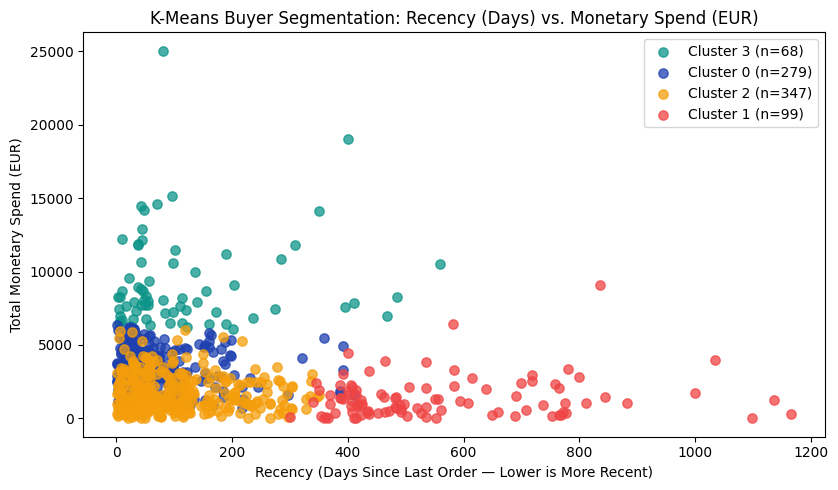

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load Transactions & Compute Customer RFM Table
sales = pd.read_csv('superstore_sales.csv')
sales['Order Date'] = pd.to_datetime(sales['Order Date'], dayfirst=True, format='mixed')

snap = sales['Order Date'].max() + pd.Timedelta(days=1)
rfm = sales.groupby(['Customer ID', 'Customer Name']).agg(
    Recency=('Order Date', lambda x: (snap - x.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()
rfm['Monetary'] = rfm['Monetary'].round(2)

print(f"Total Unique Customers Segmented: {len(rfm):,} | Total Revenue: EUR {rfm['Monetary'].sum():,.2f}\n")

# ==========================================================
# PATH 1: NORMAL SQL NTILE(4) SPEND QUARTILE BUCKETS
# Forces equal 25% headcount splits based only on Monetary spend
# ==========================================================
rfm['Normal_Spend_Quartile'] = pd.qcut(rfm['Monetary'], q=4, labels=['Q1_Low', 'Q2_Mid', 'Q3_High', 'Q4_VIP'])
path1_summary = rfm.groupby('Normal_Spend_Quartile', observed=False).agg(
    Customers=('Customer ID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary_EUR=('Monetary', 'mean'),
    Total_Revenue_EUR=('Monetary', 'sum')
).round(1)

print("--- PATH 1: NORMAL SQL NTILE(4) SPEND QUARTILES ---")
print(path1_summary, "\n")

# ==========================================================
# PATH 2: UNSUPERVISED MACHINE LEARNING (K-MEANS CLUSTERING)
# Discovers natural multi-dimensional personas across R, F, and M
# ==========================================================
X_scaled = StandardScaler().fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['ML_Cluster'] = kmeans.fit_predict(X_scaled)
sil_score = silhouette_score(X_scaled, rfm['ML_Cluster'])

path2_summary = rfm.groupby('ML_Cluster').agg(
    Customers=('Customer ID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary_EUR=('Monetary', 'mean'),
    Total_Revenue_EUR=('Monetary', 'sum')
).round(1).sort_values('Avg_Monetary_EUR', ascending=False)

print(f"--- PATH 2: K-MEANS CLUSTERING (Silhouette Score: {sil_score:.3f}) ---")
print(path2_summary, "\n")

# 3. Export Segmented Customer Table & Visual Cluster Chart
rfm.to_csv('Customer_RFM_Segments.csv', index=False)
print("Exported Customer_RFM_Segments.csv successfully.")

plt.figure(figsize=(8.5, 5))
colors = ['#0D9488', '#1E40AF', '#F59E0B', '#EF4444']
for idx, cluster_id in enumerate(path2_summary.index):
    sub = rfm[rfm['ML_Cluster'] == cluster_id]
    plt.scatter(sub['Recency'], sub['Monetary'], label=f'Cluster {cluster_id} (n={len(sub)})',
                alpha=0.75, s=45, color=colors[idx])

plt.title('K-Means Buyer Segmentation: Recency (Days) vs. Monetary Spend (EUR)')
plt.xlabel('Recency (Days Since Last Order — Lower is More Recent)')
plt.ylabel('Total Monetary Spend (EUR)')
plt.legend()
plt.tight_layout()
plt.savefig('rfm_kmeans_clusters.png', dpi=300)
plt.show()